# Empirical Asset Pricing via Machine Learning — Replication
**MSDM5054 Statistical Machine Learning, Final Project (Topic 5.1)** — Gu, Kelly & Xiu (2020, *RFS*)

Goal: predict next-month excess returns of individual U.S. stocks from 94 firm characteristics, 74 industry
dummies and 8 macro predictors (920 inputs) with linear models, dimension reduction, trees and neural networks,
evaluated with the paper's **recursive (expanding-window) scheme** on 1987–2016, and study **variable importance**.

| § | Content | Course requirement |
|---|---------|--------------------|
| 0 | Setup | — |
| 1 | Build the panel: characteristics, returns, excess returns, rank-normalisation, Welch–Goyal macro predictors | data, macro predictors |
| 2 | Recursive scheme | recursive performance evaluation |
| 3 | Linear: OLS, OLS-3 (+Huber), ENet+H, PCR, PLS | ≥ 6 methods, OLS-3, robust loss |
| 4 | Trees: RF, GBRT+H | ≥ 6 methods, robust loss |
| 5 | Neural nets NN1–NN5 | NN1–NN5 |
| 6 | Results: $R^2_{oos}$ (all / top-1000 / bottom-1000), Diebold–Mariano, variable importance, complexity | analysis, variable importance |
| 7 | (Optional) decile portfolios | not compulsory |

**Team workflow.** Zhang Qi built the panel (§1) and shared it with the code. Each member ran only their own models
(§3–§5, set `MY_MODELS`) on Kaggle or their own machine and uploaded `outputs/<model>/`; the executed
per-member notebooks are in `notebooks/runs/`.

**Running this notebook on a laptop (results only).** Put all 14 model folders into `outputs/` and run top to bottom with
`MY_MODELS = []`. Nothing is re-estimated: §1 only reads three columns of the panel, §2 only prints the sample split,
§3–§5 are skipped, and §6–§7 read the saved forecasts. A laptop with 8 GB RAM and no GPU is enough
(the full panel is loaded only if `MY_MODELS` is non-empty).

## 0. Setup

In [1]:
import os, sys, json, time, glob, shutil
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = os.path.exists("/kaggle/input")
if IN_COLAB:
    # Code package unzipped to My Drive/gkx_replication, with panel.parquet + macro.csv in data/
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/gkx_replication"
elif IN_KAGGLE:
    # Kaggle: upload gkx_replication (code + data/) as a private dataset and add it as input.
    # Code is copied to /kaggle/working so outputs/ is writable; data/ stays read-only.
    src_root = Path(glob.glob("/kaggle/input/**/src/config.py", recursive=True)[0]).parents[1]
    PROJECT_DIR = "/kaggle/working/gkx_replication"
    if not os.path.exists(PROJECT_DIR):
        shutil.copytree(src_root, PROJECT_DIR, ignore=shutil.ignore_patterns("data", "outputs*"))
        os.symlink(src_root / "data", Path(PROJECT_DIR) / "data")
else:
    PROJECT_DIR = str(Path.cwd().parent)
os.chdir(PROJECT_DIR); sys.path.insert(0, PROJECT_DIR)
assert Path("data/panel.parquet").exists() or Path("data/raw").exists(), "put panel.parquet and macro.csv into data/"
# packages needed here: numpy, pandas, pyarrow (<=17 if numpy < 2), matplotlib, openpyxl

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dataclasses import replace
from src.config import Config, CHARS, MACRO
from src import data as D, panel as P, recursive as R, metrics as M

cfg = Config()                    # paths relative to PROJECT_DIR, see src/config.py
QUICK = False                     # True: only test years 1987-1988, 1 NN per ensemble
MY_MODELS = []                    # <- each member edits this, e.g. ["OLS", "OLS+H", ...]
if QUICK:
    cfg = replace(cfg, test_end=1988, out_dir="outputs_quick", vi_years=(1987,), vi_sample=50_000)
wg = sorted(Path("data/raw").glob("PredictorData*.xls*"))
if wg:
    cfg = replace(cfg, welch_goyal=str(wg[-1]))
FIG = Path(cfg.out_dir) / "figures"; FIG.mkdir(parents=True, exist_ok=True)
TAB = Path(cfg.out_dir) / "tables"; TAB.mkdir(parents=True, exist_ok=True)
try:
    import torch
    print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
except Exception as e:
    print("torch not available here (fine for data processing):", type(e).__name__)


torch not available here (fine for data processing): OSError


## 1. Data (run once by the data owner)
**Inputs to place in `data/raw/`:**
* `datashare.csv` from `datashare_OLD.zip` (94 characteristics, `sic2`, `permno`, `DATE`; 3.7M firm-months, 1957–2016).
* `PredictorData2023.xlsx` (or the latest year) from Amit Goyal's website — monthly Welch–Goyal data.
* Only if `datashare.csv` has no return column: CRSP monthly returns from WRDS (`permno, date, ret, dlret`), set `cfg.crsp_returns`.

**Processing (paper §2.1 and Internet Appendix):**
1. *Timing.* `check_alignment` compares `mom1m` with the return column to decide whether a row's characteristics
   predict the same row's return or the next one — the single most important correctness check of the project.
2. *Target* = return − risk-free rate (`Rfree`, Welch–Goyal).
3. *Characteristics* are ranked cross-sectionally each month into $[-1,1]$; missing values are set to 0 (the median).
4. *Macro predictors* (Welch & Goyal 2008): dp = log(D12) − log(P), ep = log(E12) − log(P), bm, ntis, tbl,
   tms = lty − tbl, dfy = BAA − AAA, svar. They enter with the month in which the forecast is made (no look-ahead).
5. *Features* $z_{i,t} = (1, x_t)\otimes c_{i,t}$ plus industry dummies: 94 × 9 + 74 = 920, built on the fly (`src/panel.py`).

In [3]:
# Raw data: datashare.csv is downloaded to Colab's local disk (fast; not stored on Drive).
# The Welch-Goyal file (PredictorData20xx.xlsx) must be uploaded to data/raw/ first (only needed by Zhang Qi).
if IN_COLAB and not Path(cfg.panel_path).exists():
    LOCAL = Path("/content/datashare")
    if not list(LOCAL.rglob("*.csv")):
        LOCAL.mkdir(parents=True, exist_ok=True)
        !wget -q -O /content/datashare.zip "https://www.dropbox.com/s/zzgjdubvv23xkfp/datashare.zip?dl=1"
        !unzip -o -q /content/datashare.zip -d /content/datashare
    raw_csv = sorted(LOCAL.rglob("*.csv"), key=lambda f: f.stat().st_size)[-1]
    wg = sorted(Path("data/raw").glob("PredictorData*.xls*"))[-1]
    print("datashare:", raw_csv, f"({raw_csv.stat().st_size/1e9:.2f} GB) | Welch-Goyal:", wg)
    cfg = replace(cfg, raw_csv=str(raw_csv), welch_goyal=str(wg))

In [4]:
# Build the panel once (data owner only). Loading the full panel needs several GB of RAM, so it is done
# only when this machine is going to estimate models (MY_MODELS non-empty); results (§6-§7) do not need it.
if not Path(cfg.panel_path).exists():
    t0 = time.time()
    D.build_panel(cfg)              # ~15-30 min; prints the timing (alignment) check
    print(f"built in {(time.time()-t0)/60:.1f} min")
pan = P.Panel(cfg) if MY_MODELS else None
print("panel loaded" if pan is not None else "panel not loaded (results-only run)")

panel not loaded (results-only run)


In [5]:
# Data checks -> post these numbers in the group chat and use them in report Section 2 / Table 1
pq = pd.read_parquet(cfg.panel_path, columns=["permno", "ret_month", "ret_exc", "size_raw"])
n_month = pq.groupby("ret_month").size()
print(f"rows {len(pq):,} | stocks {pq.permno.nunique():,} | months {len(n_month)} | avg stocks/month {n_month.mean():,.0f}")
print(f"period {pq.ret_month.min():%Y-%m} to {pq.ret_month.max():%Y-%m}")
print(f"excess return: mean {100*pq.ret_exc.mean():.2f}% / month, std {100*pq.ret_exc.std():.2f}%")
q = pq.size_raw.quantile([.01, .5, .99]).round(2).to_dict()
print("mvel1 raw quantiles:", q, "-> LOG scale" if pq.size_raw.max() < 50 else "-> LEVELS")
print("timing check:", json.load(open("data/alignment.json")) if Path("data/alignment.json").exists() else "see build log")
del pq

rows 4,339,257 | stocks 31,913 | months 1128 | avg stocks/month 3,847
period 1927-01 to 2020-12
excess return: mean 0.74% / month, std 17.42%
mvel1 raw quantiles: {0.01: 952.3099975585938, 0.5: 83721.7890625, 0.99: 24764346.0} -> LEVELS
timing check: {'return_column': 'RET', 'corr_same': 0.003952075850726204, 'corr_next': 0.9999497207596317, 'shift': 0.0}


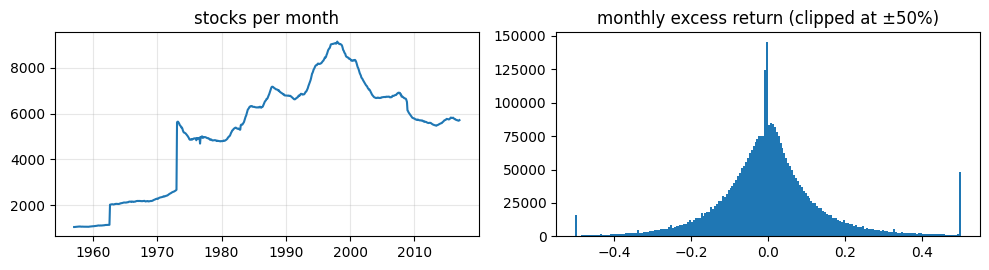

firm-months            3762139.000
stocks                   29925.000
avg stocks / month        5225.193
mean excess ret (%)          0.673
std (%)                     17.446
skew                         6.422
excess kurtosis            323.301
dtype: float64

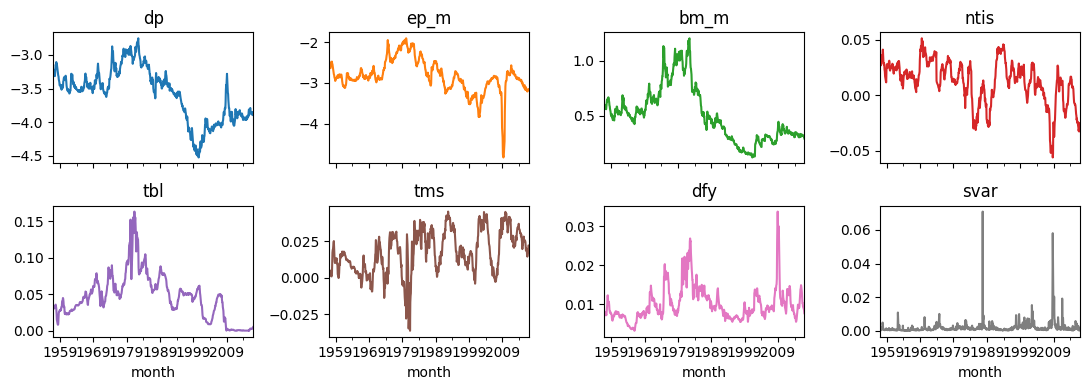

In [6]:
# Sample description for report Table 1 / Section 2 -- paper sample 1957-2016, three columns only
pq = pd.read_parquet(cfg.panel_path, columns=["permno", "ret_month", "ret_exc"])
pq = pq[(pq.ret_month >= "1957-01-01") & (pq.ret_month <= "2016-12-31")]
per_month = pq.groupby("ret_month").size()
fig, ax = plt.subplots(1, 2, figsize=(10, 2.8))
ax[0].plot(per_month.index, per_month.values); ax[0].set_title("stocks per month"); ax[0].grid(alpha=.3)
ax[1].hist(np.clip(pq.ret_exc, -0.5, 0.5), bins=200); ax[1].set_title("monthly excess return (clipped at ±50%)")
plt.tight_layout(); plt.savefig(FIG / "sample.pdf", bbox_inches="tight"); plt.show()
desc = pd.Series({"firm-months": len(pq), "stocks": pq.permno.nunique(), "avg stocks / month": per_month.mean(),
                  "mean excess ret (%)": 100*pq.ret_exc.mean(), "std (%)": 100*pq.ret_exc.std(),
                  "skew": pq.ret_exc.skew(), "excess kurtosis": pq.ret_exc.kurt()})
display(desc.round(3)); desc.to_csv(TAB / "sample_description.csv")
macro = pd.read_csv(cfg.macro_path, index_col=0)
macro.index = pd.PeriodIndex(macro.index, freq="M").to_timestamp()
macro.loc["1957":"2016", MACRO].plot(subplots=True, layout=(2, 4), figsize=(11, 4), legend=False, title=MACRO, sharex=True)
plt.tight_layout(); plt.savefig(FIG / "macro.pdf", bbox_inches="tight"); plt.show()

## 2. Recursive performance evaluation
Refit every year $Y = 1987,\dots,2016$: training $1957\ldots Y-13$ (expanding), validation the 12 years before $Y$ (rolling),
test year $Y$. Hyper-parameters are chosen on the validation sample only; the test year is never touched before forecasting.

In [7]:
# Recursive splits (sizes counted from one column of the panel)
yrs = pd.read_parquet(cfg.panel_path, columns=["ret_month"])["ret_month"].dt.year.value_counts().sort_index()
splits = pd.DataFrame([dict(zip(["train", "validation", "test"], cfg.split(Y))) for Y in cfg.refit_years()],
                      index=cfg.refit_years())
splits["n_train"] = [int(yrs.loc[s[0]:s[1]].sum()) for s in splits.train]
splits["n_validation"] = [int(yrs.loc[s[0]:s[1]].sum()) for s in splits.validation]
display(splits.iloc[[0, 1, 2, -1]])

,train,validation,test,n_train,n_validation
1987,"(1957, 1974)","(1975, 1986)","(1987, 1987)",479467,773887
1988,"(1957, 1975)","(1976, 1987)","(1988, 1988)",538166,798511
1989,"(1957, 1976)","(1977, 1988)","(1989, 1989)",597175,824214
2016,"(1957, 2003)","(2004, 2015)","(2016, 2016)",2812624,880730


## 3. Linear models
* **OLS** with all 920 inputs, and **OLS-3** with size (`mvel1`), book-to-market (`bm`) and momentum (`mom12m`), each with
  least squares and with the **Huber loss** (+H, $\xi$ = 99.9% quantile of absolute residuals, IRLS).
* **ENet+H**: elastic net ($\rho=0.5$, $\lambda\in[10^{-4},10^{-1}]$ on standardised inputs) on the Huber-weighted Gram matrix.
* **PCR / PLS**: number of components chosen on the validation sample (PLS = Krylov subspace of $\Sigma_{xx}$ and $\sigma_{xy}$).

All are fitted from streamed $Z^\top WZ$ and $Z^\top Wy$ (921×921), so the 920-column design matrix is never stored.

In [8]:
for name in [m for m in MY_MODELS if m in ("OLS", "OLS+H", "OLS-3", "OLS-3+H", "ENet+H", "PCR", "PLS")]:
    R.run_model(name, pan, cfg)

### 3b. Precision check for OLS / OLS+H (CPU, float64)
With all 920 inputs, OLS and OLS+H give R²_oos of −22.5% / −23.5% (GKX: −3.46% for OLS+H). The team ran them on a GPU,
where the Gram matrix is built from float32 products. With nearly collinear inputs that could matter. This cell
re-estimates the three worst test years (1987, 1988, 1994) on the CPU in float64 and compares them with the team run.

* Set `RUN_OLS_CHECK = True`. It takes about 20 minutes on a laptop and needs ~3 GB of RAM (it loads the panel in memory-light mode).
* **Verdict "same"**: the large negative R² is genuine (extrapolation along nearly collinear inputs). Keep the results.
* **Verdict "different"**: precision matters. Re-run OLS and OLS+H for all years on a GPU with `src.linear.GPU_FLOAT64 = True`
  (cell 3c), and replace the two folders in `outputs/`.

In [9]:
RUN_OLS_CHECK = False
CHECK_YEARS = [1987, 1988, 1994]
if RUN_OLS_CHECK:
    import src.linear as L
    L._torch_cuda = lambda: False                       # force the numpy float64 path
    pan_chk = pan if pan is not None else P.Panel(cfg)
    cfg_chk = replace(cfg, out_dir="outputs_olscheck", chunk=50_000)
    for m in ["OLS", "OLS+H"]:
        R.run_model(m, pan_chk, cfg_chk, years=CHECK_YEARS, vi=False)
    new = M.r2_by_year(cfg_chk.out_dir, ["OLS", "OLS+H"])
    old = M.r2_by_year(cfg.out_dir, ["OLS", "OLS+H"]).reindex(new.index)
    chk = pd.concat({"team run (GPU float32)": old, "check (CPU float64)": new}, axis=1).round(2)
    display(chk); chk.to_csv(TAB / "ols_precision_check.csv")
    rel = ((new - old).abs() / old.abs()).max().max()
    print(f"largest relative difference: {rel:.1%}")
    print("VERDICT:", "different -> precision matters; re-run OLS and OLS+H with GPU_FLOAT64 = True (cell 3c)"
          if rel > 0.2 else "same -> the large negative R2 of OLS/OLS+H is genuine, not a precision artefact; keep the results")
    del pan_chk

### 3c. Only if the check says "different": re-run OLS and OLS+H in float64 (GPU, ~1 h)
Run on Kaggle or Colab with a GPU, with `MY_MODELS = []` and the old `OLS` and `OLS+H` folders moved out of `outputs/`.

In [10]:
RUN_OLS_FLOAT64 = False
if RUN_OLS_FLOAT64:
    import src.linear as L
    L.GPU_FLOAT64 = True
    pan_f64 = pan if pan is not None else P.Panel(cfg)
    for m in ["OLS", "OLS+H"]:
        R.run_model(m, pan_f64, cfg)

## 4. Tree models
* **RF**: 300 trees, depth ∈ {2, 4, 6}, features per split ∈ {10, 30}.
* **GBRT+H**: depth ∈ {1, 2}, learning rate ∈ {0.01, 0.1}, up to 1000 trees with early stopping on validation, pseudo-Huber loss.

Inputs: 94 characteristics + sic2 (95 inputs). The macro predictors are not given to the trees as standalone levels: in GKX they enter only through interactions with characteristics. A first specification with the 8 macro levels as extra inputs (103 inputs) forecast the market-wide component of returns and gave negative R² (RF −0.66%, GBRT+H −0.11%); see README.
`tune_every=5` re-tunes every 5 refits to save GPU time (set 1 to follow the paper exactly).

In [11]:
for name in [m for m in MY_MODELS if m in ("RF", "GBRT+H")]:
    R.run_model(name, pan, cfg, tune_every=5)

### 4b. Tree variable importance with the monthly-median fill (Tang Yunshu, ~10 min)
GKX set an input to zero, which is the median of a rank-normalised *continuous* characteristic. For binary or heavily tied
characteristics (divi, divo, sin, convind …), the "0" group sits slightly below zero, while missing values are exactly 0.
Zeroing such an input therefore marks every stock as "missing", and trees pick this up as importance. This cell
recomputes the tree VI by setting each characteristic to its monthly cross-sectional median instead. That is identical to
zero for continuous characteristics. Only `vi_*.csv` are rewritten; the forecasts are unchanged. It needs xgboost and the panel.

In [12]:
RUN_TREE_VI_MEDIAN = False
if RUN_TREE_VI_MEDIAN:
    pan_vi = pan if pan is not None else P.Panel(cfg)
    for m in ["RF", "GBRT+H"]:
        R.rerun_vi(m, pan_vi, cfg, fill="median")

## 5. Neural networks NN1–NN5
Hidden layers 32 / 32-16 / 32-16-8 / 32-16-8-4 / 32-16-8-4-2, ReLU, batch norm, L1 penalty ∈ {1e-5, 1e-4, 1e-3},
Adam with learning rate ∈ {0.001, 0.01}, batch 10,000, ≤ 100 epochs, early stopping (patience 5), ensemble of networks
with different seeds (paper: 10). Splitting NN1–NN5 across team members' Colab/Kaggle GPUs is the easiest speed-up.

In [13]:
NN_KW = dict(n_ensemble=1 if QUICK else 5)     # 10 in the paper; 5 halves the cost
for name in [m for m in MY_MODELS if m.startswith("NN")]:
    R.run_model(name, pan, cfg, tune_every=5, **NN_KW)

## 6. Results
Run after all 14 model folders are in `outputs/`. $R^2_{oos} = 1-\sum(r-\hat r)^2/\sum r^2$ — benchmark is a **zero** forecast,
not the historical mean (the paper argues the historical mean is so noisy that it would flatter weak models).

In [17]:
# 1) Put all 14 model folders directly into outputs/ (outputs/OLS, outputs/RF, ...).
#    If they are still inside downloaded / unzipped team folders, list those folders here, newest upload LAST,
#    and run this cell once: each model folder is copied into outputs/ (an existing one is replaced).
SOURCES = []        # e.g. [r"C:\Users\dell\Downloads\OneDrive_1_2026-11-20", r"C:\Users\dell\Downloads\outputs_1"]
EXTRA_FILES = {}    # single files to add, e.g. {"NN3": [r"C:\Users\dell\Downloads\pred_1991.parquet"]}
if SOURCES:
    display(M.collect_outputs(SOURCES, cfg.out_dir))
for m, files in EXTRA_FILES.items():
    for f in files:
        shutil.copy(f, Path(cfg.out_dir) / m)
# 2) Completeness: test years actually covered by each model's forecasts (30 = 1987-2016)
cov = M.coverage(cfg.out_dir)
display(cov); cov.to_csv(TAB / "coverage.csv")
if (cov["test years"] < 30).any():
    print("WARNING: incomplete models:", cov.index[cov["test years"] < 30].tolist())

,test years,missing,VI files
OLS,30,-,6
OLS+H,30,-,6
OLS-3,30,-,6
OLS-3+H,30,-,6
PLS,30,-,6
PCR,30,-,6
ENet+H,30,-,6
RF,30,-,6
GBRT+H,30,-,6
NN1,30,-,6


,All,Top 1000,Bottom 1000,years,Paper (All)
OLS,-22.49,-103.35,-9.43,1987-2016,NaN
OLS+H,-23.48,-110.65,-9.94,1987-2016,-3.46
OLS-3,0.20,0.23,0.19,1987-2016,NaN
OLS-3+H,0.19,0.24,0.17,1987-2016,0.16
PLS,0.20,-0.59,0.40,1987-2016,0.27
PCR,0.28,-0.00,0.38,1987-2016,0.26
ENet+H,0.07,-0.14,0.21,1987-2016,0.11
RF,0.08,-0.08,0.21,1987-2016,0.33
GBRT+H,0.11,0.21,0.12,1987-2016,0.34
NN1,0.34,0.36,0.52,1987-2016,0.33


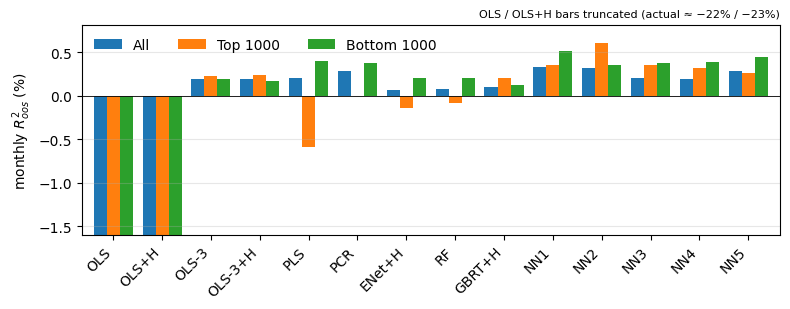

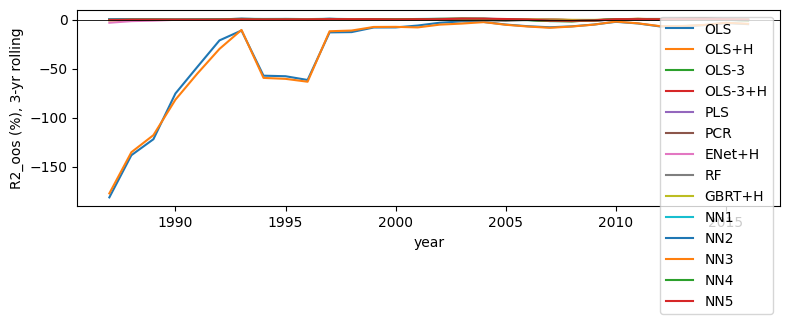

In [18]:
r2 = M.r2_table(cfg.out_dir)
display(r2.round(2))
M.to_latex(r2[["All", "Top 1000", "Bottom 1000", "Paper (All)"]], TAB / "tab_r2.tex")
M.plot_r2(r2, FIG / "r2_oos.pdf")
yr = M.r2_by_year(cfg.out_dir); yr.to_csv(TAB / "r2_by_year.csv")
ax = yr.rolling(3, min_periods=1).mean().plot(figsize=(8, 3)); ax.axhline(0, c="k", lw=.6)
ax.set_ylabel("R2_oos (%), 3-yr rolling"); plt.tight_layout(); plt.savefig(FIG / "r2_by_year.pdf", bbox_inches="tight")

In [19]:
# Diebold-Mariano tests (paper Table 3 order). Positive: column model beats row model.
# |DM| > 1.96: 5% level; |DM| > 2.64: Bonferroni-adjusted for 12 comparisons (GKX).
order = [m for m in ["OLS+H", "OLS-3+H", "PLS", "PCR", "ENet+H", "RF", "GBRT+H", "NN1", "NN2", "NN3", "NN4", "NN5"]
         if (Path(cfg.out_dir) / m).exists()]
dm = M.dm_matrix(cfg.out_dir, order)
print("months used (common sample):", dm.attrs["n_months"])
up = dm.where(np.triu(np.ones(dm.shape, bool), 1))
display(up.round(2))
M.to_latex(up.iloc[:-1, 1:], TAB / "tab_dm.tex")

months used (common sample): 360


,OLS+H,OLS-3+H,PLS,PCR,ENet+H,RF,GBRT+H,NN1,NN2,NN3,NN4,NN5
OLS+H,NaN,4.24,4.23,4.25,4.28,4.20,4.22,4.25,4.26,4.26,4.26,4.27
OLS-3+H,NaN,NaN,0.03,2.53,-0.99,-0.92,-1.64,0.97,1.09,0.04,-0.02,1.03
PLS,NaN,NaN,NaN,1.77,-0.95,-0.88,-0.92,1.17,1.18,0.03,-0.04,0.95
PCR,NaN,NaN,NaN,NaN,-1.59,-1.67,-2.45,0.19,0.18,-0.48,-0.61,0.01
ENet+H,NaN,NaN,NaN,NaN,NaN,0.05,0.30,1.53,2.03,0.89,0.87,1.82
RF,NaN,NaN,NaN,NaN,NaN,NaN,0.25,1.64,1.44,0.63,0.60,1.21
GBRT+H,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.48,1.71,0.52,0.52,1.81
NN1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.01,-0.85,-1.07,-0.18
NN2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.11,-1.37,-0.25
NN3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.14,0.66


'\\begin{tabular}{lrrrrrrrrrrr}\n\\toprule\n & OLS-3+H & PLS & PCR & ENet+H & RF & GBRT+H & NN1 & NN2 & NN3 & NN4 & NN5 \\\\\n\\midrule\nOLS+H & 4.24 & 4.23 & 4.25 & 4.28 & 4.20 & 4.22 & 4.25 & 4.26 & 4.26 & 4.26 & 4.27 \\\\\nOLS-3+H & -- & 0.03 & 2.53 & -0.99 & -0.92 & -1.64 & 0.97 & 1.09 & 0.04 & -0.02 & 1.03 \\\\\nPLS & -- & -- & 1.77 & -0.95 & -0.88 & -0.92 & 1.17 & 1.18 & 0.03 & -0.04 & 0.95 \\\\\nPCR & -- & -- & -- & -1.59 & -1.67 & -2.45 & 0.19 & 0.18 & -0.48 & -0.61 & 0.01 \\\\\nENet+H & -- & -- & -- & -- & 0.05 & 0.30 & 1.53 & 2.03 & 0.89 & 0.87 & 1.82 \\\\\nRF & -- & -- & -- & -- & -- & 0.25 & 1.64 & 1.44 & 0.63 & 0.60 & 1.21 \\\\\nGBRT+H & -- & -- & -- & -- & -- & -- & 1.48 & 1.71 & 0.52 & 0.52 & 1.81 \\\\\nNN1 & -- & -- & -- & -- & -- & -- & -- & -0.01 & -0.85 & -1.07 & -0.18 \\\\\nNN2 & -- & -- & -- & -- & -- & -- & -- & -- & -1.11 & -1.37 & -0.25 \\\\\nNN3 & -- & -- & -- & -- & -- & -- & -- & -- & -- & -0.14 & 0.66 \\\\\nNN4 & -- & -- & -- & -- & -- & -- & -- & -- & -- & 

mom1m              0.208
mom12m             0.113
mvel1              0.093
turn               0.045
chmom              0.044
divi               0.041
retvol             0.039
std_turn           0.032
maxret             0.029
betasq             0.029
beta               0.029
pchsaleinv         0.027
pchsale_pchinvt    0.027
indmom             0.024
bm                 0.024
dolvol             0.021
divo               0.019
mom6m              0.016
ill                0.013
zerotrade          0.013
dtype: float64

,OLS,OLS+H,OLS-3,OLS-3+H,PLS,PCR,ENet+H,RF,GBRT+H,NN1,NN2,NN3,NN4,NN5
dp,0.634,0.644,0.0,0.0,0.006,0.135,0.047,0.0,0.0,0.574,0.689,0.600,0.637,0.727
ep_m,0.274,0.259,0.0,0.0,0.017,0.116,0.050,0.0,0.0,0.306,0.187,0.249,0.251,0.168
bm_m,0.066,0.070,0.0,0.0,0.160,0.188,0.301,0.0,0.0,0.121,0.123,0.151,0.111,0.105
ntis,0.001,0.001,0.0,0.0,0.055,0.000,0.063,0.0,0.0,0.000,0.000,0.000,0.000,0.000
tbl,0.018,0.019,0.0,0.0,0.369,0.190,0.293,0.0,0.0,0.000,0.000,0.000,0.000,0.000
tms,0.001,0.001,0.0,0.0,0.048,0.013,0.014,0.0,0.0,0.000,0.000,0.000,0.000,0.000
dfy,0.005,0.006,0.0,0.0,0.257,0.144,0.150,0.0,0.0,0.000,0.000,0.000,0.000,0.000
svar,0.000,0.000,0.0,0.0,0.088,0.215,0.082,0.0,0.0,0.000,0.000,0.000,0.000,0.000


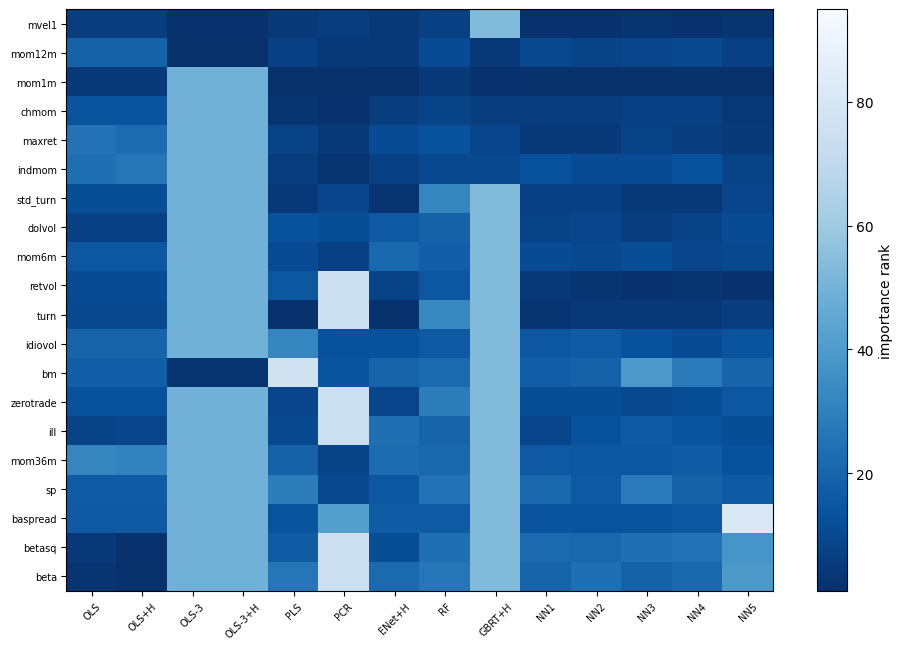

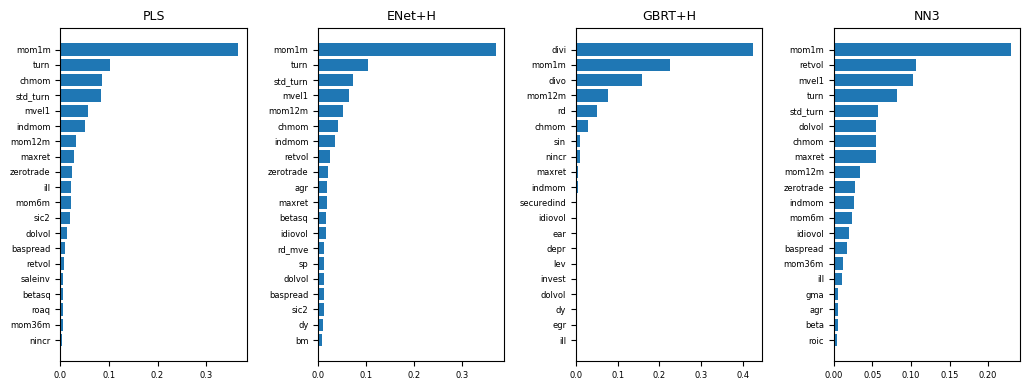

In [20]:
ch, mc = M.variable_importance(cfg.out_dir)
display(ch.mean(1).sort_values(ascending=False).head(20).round(3))
M.plot_vi_heatmap(ch, top=20, path=FIG / "vi_heatmap.pdf")
show = [m for m in ["PLS", "ENet+H", "GBRT+H", "NN3"] if m in ch]
if show: M.plot_vi_bars(ch, show, top=20, path=FIG / "vi_bars.pdf")
display(mc.round(3)); M.to_latex(mc, TAB / "tab_vi_macro.tex", fmt="%.3f")
ch.to_csv(TAB / "vi_chars.csv")

In [21]:
# Characteristic categories (paper's grouping idea): how much importance goes to each family of signals?
GROUPS = {
    "price trend": ["mom1m", "mom6m", "mom12m", "mom36m", "chmom", "indmom", "maxret"],
    "liquidity": ["mvel1", "dolvol", "std_dolvol", "turn", "std_turn", "ill", "zerotrade", "baspread"],
    "risk / volatility": ["retvol", "idiovol", "beta", "betasq"],
    "valuation / fundamentals": ["bm", "ep", "sp", "cfp", "dy", "agr", "roaq", "roeq", "sgr", "lev"],
}
grp = pd.DataFrame({g: ch.loc[[c for c in cs if c in ch.index]].sum() for g, cs in GROUPS.items()})
grp["other"] = 1 - grp.sum(1)
display(grp.round(3)); M.to_latex(grp, TAB / "tab_vi_groups.tex", fmt="%.2f")

,price trend,liquidity,risk / volatility,valuation / fundamentals,other
OLS,0.055,0.093,0.352,0.018,0.483
OLS+H,0.071,0.116,0.407,0.023,0.383
OLS-3,0.583,0.282,0.000,0.135,0.000
OLS-3+H,0.569,0.279,0.000,0.152,0.000
PLS,0.587,0.318,0.019,0.011,0.065
PCR,0.853,0.054,0.006,0.033,0.054
ENet+H,0.529,0.291,0.065,0.052,0.062
RF,0.203,0.089,0.038,0.051,0.619
GBRT+H,0.341,0.000,0.000,0.000,0.659
NN1,0.486,0.366,0.094,0.021,0.034


'\\begin{tabular}{lrrrrr}\n\\toprule\n & price trend & liquidity & risk / volatility & valuation / fundamentals & other \\\\\n\\midrule\nOLS & 0.05 & 0.09 & 0.35 & 0.02 & 0.48 \\\\\nOLS+H & 0.07 & 0.12 & 0.41 & 0.02 & 0.38 \\\\\nOLS-3 & 0.58 & 0.28 & 0.00 & 0.13 & 0.00 \\\\\nOLS-3+H & 0.57 & 0.28 & 0.00 & 0.15 & 0.00 \\\\\nPLS & 0.59 & 0.32 & 0.02 & 0.01 & 0.07 \\\\\nPCR & 0.85 & 0.05 & 0.01 & 0.03 & 0.05 \\\\\nENet+H & 0.53 & 0.29 & 0.07 & 0.05 & 0.06 \\\\\nRF & 0.20 & 0.09 & 0.04 & 0.05 & 0.62 \\\\\nGBRT+H & 0.34 & 0.00 & 0.00 & 0.00 & 0.66 \\\\\nNN1 & 0.49 & 0.37 & 0.09 & 0.02 & 0.03 \\\\\nNN2 & 0.50 & 0.33 & 0.12 & 0.02 & 0.04 \\\\\nNN3 & 0.43 & 0.35 & 0.14 & 0.02 & 0.05 \\\\\nNN4 & 0.42 & 0.35 & 0.13 & 0.03 & 0.07 \\\\\nNN5 & 0.54 & 0.24 & 0.12 & 0.03 & 0.07 \\\\\n\\bottomrule\n\\end{tabular}\n'

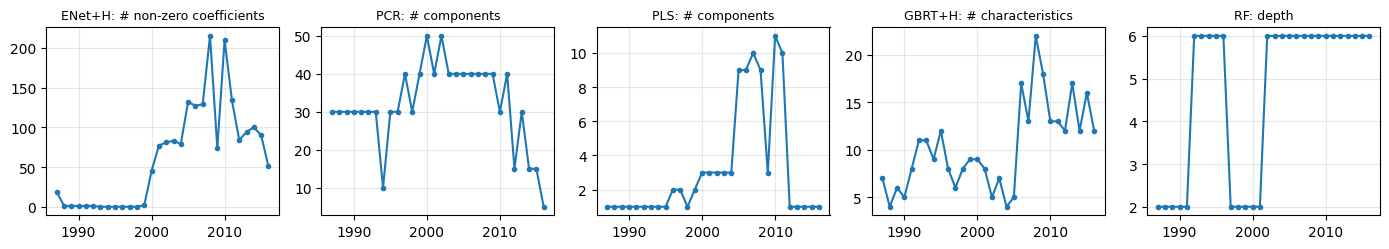

In [22]:
# Model complexity over time (paper Figure 3) -- linear models; tree keys are used only if present
series = {}
for model, key, label in [("ENet+H", "n_nonzero", "ENet+H: # non-zero coefficients"), ("PCR", "param", "PCR: # components"),
                          ("PLS", "param", "PLS: # components"), ("GBRT+H", "n_features_used", "GBRT+H: # characteristics"),
                          ("RF", "max_depth", "RF: depth")]:
    s = M.hparam_history(cfg.out_dir, model, key)
    if len(s): series[label] = s
if series: M.plot_complexity(series, FIG / "complexity.pdf")

## 7. (Optional) Decile portfolios — not compulsory for the course

In [23]:
r2 = r2 if 'r2' in globals() else M.r2_table(cfg.out_dir)
rows = {}
for m in [x for x in ["OLS-3+H", "PLS", "ENet+H", "RF", "GBRT+H", "NN3"] if x in r2.index]:
    ew, vw = M.decile_portfolios(cfg.out_dir, m, "ew"), M.decile_portfolios(cfg.out_dir, m, "vw")
    rows[m] = {"EW H-L mean (%)": 100*ew["H-L"].mean(), "EW Sharpe": M.sharpe(ew["H-L"]),
               "VW H-L mean (%)": 100*vw["H-L"].mean(), "VW Sharpe": M.sharpe(vw["H-L"])}
port = pd.DataFrame(rows).T; display(port.round(2)); M.to_latex(port, TAB / "tab_portfolios.tex")

,EW H-L mean (%),EW Sharpe,VW H-L mean (%),VW Sharpe
OLS-3+H,1.42,0.81,0.75,0.42
PLS,2.33,1.59,0.93,0.68
ENet+H,1.93,1.02,0.59,0.36
RF,1.95,1.49,0.40,0.31
GBRT+H,0.53,0.51,0.18,0.16
NN3,2.68,1.81,1.56,0.94


'\\begin{tabular}{lrrrr}\n\\toprule\n & EW H-L mean (%) & EW Sharpe & VW H-L mean (%) & VW Sharpe \\\\\n\\midrule\nOLS-3+H & 1.42 & 0.81 & 0.75 & 0.42 \\\\\nPLS & 2.33 & 1.59 & 0.93 & 0.68 \\\\\nENet+H & 1.93 & 1.02 & 0.59 & 0.36 \\\\\nRF & 1.95 & 1.49 & 0.40 & 0.31 \\\\\nGBRT+H & 0.53 & 0.51 & 0.18 & 0.16 \\\\\nNN3 & 2.68 & 1.81 & 1.56 & 0.94 \\\\\n\\bottomrule\n\\end{tabular}\n'